# Gradient-boosting baseline: tests and results

This notebook looks only at the gradient-boosting statistics baseline (`scripts/run_gradient_boosting.py`,
`config/gradient_boosting.json`). It reads the frozen shared dataset in `data/processed/` and the saved model in
`data/models/gradient_boosting/model.joblib`. It writes nothing back.

**Split rule.** TRAIN = 2012–13 to 2023–24, DEV = 2024–25, TEST = 2025–26. TEST was scored once by the saved,
DEV-selected model, so TEST numbers here are only that model's stored forecasts. Every new experiment in this
notebook (other settings, feature subsets, training windows) is fitted on TRAIN and scored on **DEV only**.

| # | Test | Model used |
| --- | --- | --- |
| 1 | Integrity: the saved model reproduces the published forecasts; no DEV/TEST game in any fit | saved model |
| 2 | Headline DEV/TEST scores against simple baselines, with day-clustered bootstrap intervals | saved model |
| 3 | Calibration (reliability curves, expected calibration error) | saved model |
| 4 | Walk-forward TRAIN forecasts by season | saved prior-season models |
| 5 | DEV selection among the four configured candidates | stored run record |
| 6 | Feature importance: impurity and grouped permutation on DEV | saved model |
| 7 | Wider hyperparameter sweep | histogram boosting, DEV only |
| 8 | Feature-group ablation | histogram boosting, DEV only |
| 9 | Training-window length | histogram boosting, DEV only |
| 10 | Error analysis: by month, confidence and biggest misses | saved model |
| 11 | Why the most confident misses happened (who sat, what the market said) | saved model + postgame box scores |
| 12 | Polymarket comparison: scores, divergences, orthogonality | saved model + market prices |
| — | Data history: how far back, would more seasons help | Test 9 curve |

Tests 7–9 use scikit-learn's `HistGradientBoostingClassifier`, because one fit of the project's exact
`GradientBoostingClassifier` on 13k games × 252 features takes about four minutes. Test 7 first checks that the
fast model scores close to the exact one at the selected settings.

In [1]:
import json, sys, time
from collections import Counter, defaultdict
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingClassifier

ROOT = Path.cwd().resolve()
while not (ROOT / "config/gradient_boosting.json").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import run_gradient_boosting as rgb
from nba_dataset import Dataset

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3})
CONFIG = json.loads(rgb.CONFIG_PATH.read_text())
RECORD = json.loads((rgb.REPORT_DIR / "metrics.json").read_text())

started = time.time()
dataset = Dataset(ROOT)
inputs = dataset.inputs()
labels = dataset.labels(rgb.SPLITS)
X, y = rgb.arrays(inputs, labels)
NAMES = list(rgb.FEATURE_NAMES)
split = np.array([r["split"] for r in inputs])
season = np.array([r["season"] for r in inputs])
dates = np.array([r["game_date_et"] for r in inputs])
ids = np.array([r["game_id"] for r in inputs])
teams = np.array([f"{r['away_abbr']} @ {r['home_abbr']}" for r in inputs])
TRAIN, DEV, TEST = (split == s for s in rgb.SPLITS)

stored = {r["game_id"]: r for r in dataset.predictions("gradient_boosting")}
p = np.array([stored[g]["p_boost"] if g in stored else np.nan for g in ids])
bundle = joblib.load(rgb.MODEL_PATH)
final = bundle["final"]["model"]

def score(mask, prob=None):
    return rgb.score_predictions(y[mask], p[mask] if prob is None else prob)

def table(rows, columns, formats=None):
    formats = formats or {}
    out = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    for row in rows:
        out.append("| " + " | ".join(format(row[c], formats.get(c, "")) if row[c] is not None else "" for c in columns) + " |")
    display(Markdown("\n".join(out)))

print(f"Loaded {len(ids):,} eligible games x {X.shape[1]} features in {time.time() - started:.0f}s; dataset {dataset.manifest['dataset_id'][:12]}")
print("Games per split:", dict(Counter(split)))
print("Saved model settings:", {k: bundle['settings'][k] for k in ('max_depth', 'n_estimators', 'learning_rate', 'min_samples_leaf')})

Loaded 15,717 eligible games x 252 features in 22s; dataset 4e5ba4eb0554
Games per split: {np.str_('train'): 13457, np.str_('dev'): 1123, np.str_('test'): 1137}
Saved model settings: {'max_depth': 2, 'n_estimators': 200, 'learning_rate': 0.05, 'min_samples_leaf': 20}


## Data overview

| season | split | games | home_win_rate | missing_feature_share |
|---|---|---|---|---|
| 2012–13 | TRAIN | 1,149 | 0.611 | 5.4% |
| 2013–14 | TRAIN | 1,153 | 0.573 | 6.3% |
| 2014–15 | TRAIN | 1,151 | 0.573 | 5.9% |
| 2015–16 | TRAIN | 1,152 | 0.598 | 5.1% |
| 2016–17 | TRAIN | 1,151 | 0.583 | 5.3% |
| 2017–18 | TRAIN | 1,150 | 0.579 | 9.8% |
| 2018–19 | TRAIN | 1,151 | 0.590 | 3.7% |
| 2019–20 | TRAIN | 982 | 0.550 | 1.6% |
| 2020–21 | TRAIN | 1,000 | 0.549 | 3.9% |
| 2021–22 | TRAIN | 1,152 | 0.547 | 0.3% |
| 2022–23 | TRAIN | 1,151 | 0.579 | 0.8% |
| 2023–24 | TRAIN | 1,115 | 0.542 | 5.1% |
| 2024–25 | DEV | 1,123 | 0.550 | 3.9% |
| 2025–26 | TEST | 1,137 | 0.550 | 2.3% |

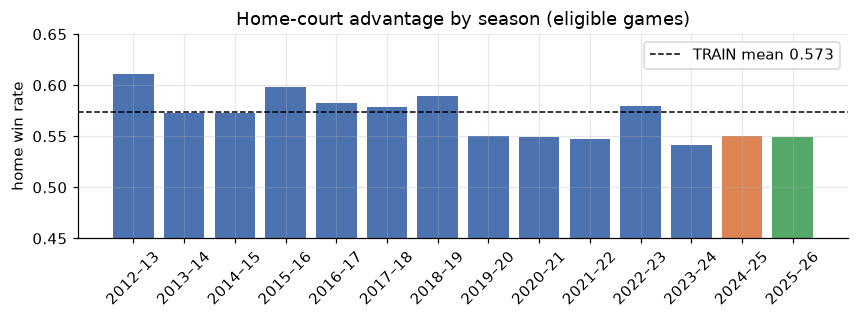

In [2]:
rows = []
for s in sorted(set(season)):
    m = season == s
    rows.append({"season": rgb.season_label(int(s)), "split": split[m][0].upper(), "games": int(m.sum()),
                 "home_win_rate": y[m].mean(), "missing_feature_share": np.isnan(X[m]).mean()})
table(rows, ["season", "split", "games", "home_win_rate", "missing_feature_share"],
      {"games": ",", "home_win_rate": ".3f", "missing_feature_share": ".1%"})

fig, ax = plt.subplots(figsize=(8, 3))
colors = {"TRAIN": "#4C72B0", "DEV": "#DD8452", "TEST": "#55A868"}
ax.bar([r["season"] for r in rows], [r["home_win_rate"] for r in rows], color=[colors[r["split"]] for r in rows])
ax.axhline(y[TRAIN].mean(), color="k", lw=1, ls="--", label=f"TRAIN mean {y[TRAIN].mean():.3f}")
ax.set_ylim(.45, .65); ax.set_ylabel("home win rate"); ax.legend(); ax.tick_params(axis="x", rotation=45)
ax.set_title("Home-court advantage by season (eligible games)"); plt.tight_layout(); plt.show()

## Test 1: integrity of the saved model and forecasts

Checks: (a) the saved TRAIN-fit model reproduces the published DEV and TEST `p_boost`; (b) each saved
prior-season model reproduces the published TRAIN forecasts of its season; (c) the final fit used exactly the TRAIN
games, selection used exactly DEV, and no DEV or TEST game is in any fit; (d) every prior-season model was fitted only
on earlier seasons; (e) the saved model file matches the checksum pinned by the dataset release and the run record.
(The run record's code hashes predate the move to the shared dataset; `validate_gradient_boosting.py` checks that history.)

In [3]:
checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})

recomputed = final.predict_proba(X[~TRAIN])[:, 1]
diff = np.abs(recomputed - p[~TRAIN]).max()
check("DEV/TEST forecasts reproduce", diff < 1e-12, f"max |diff| = {diff:.1e} over {(~TRAIN).sum():,} games")
worst = 0.0
for s, entry in bundle["prior_seasons"].items():
    m = TRAIN & (season == s)
    worst = max(worst, np.abs(entry["model"].predict_proba(X[m])[:, 1] - p[m]).max())
check("TRAIN walk-forward forecasts reproduce", worst < 1e-12, f"max |diff| = {worst:.1e}, {len(bundle['prior_seasons'])} season models")
fit_ids, sel_ids = set(bundle["final"]["fit_game_ids"]), set(bundle["final"]["selection_game_ids"])
check("final fit = TRAIN games", fit_ids == set(ids[TRAIN]), f"{len(fit_ids):,} games")
check("selection = DEV games", sel_ids == set(ids[DEV]), f"{len(sel_ids):,} games")
held_out = set(ids[DEV | TEST])
leaks = sum(len(held_out & set(e["fit_game_ids"])) for e in bundle["prior_seasons"].values()) + len(held_out & fit_ids)
check("no DEV/TEST game in any fit", leaks == 0, f"{leaks} overlapping games")
season_of = dict(zip(ids, season))
ok = all(max(season_of[g] for g in e["fit_game_ids"]) < s for s, e in bundle["prior_seasons"].items())
check("prior-season models use earlier seasons only", ok)
check("no TRAIN forecasts for the first season", np.isnan(p[TRAIN & (season == season[TRAIN].min())]).all(),
      f"{int(np.isnan(p[TRAIN]).sum()):,} unforecast 2012-13 games")
model_key = "data/models/gradient_boosting/model.joblib"
digest = rgb.sha256(rgb.MODEL_PATH)
check("saved model = dataset release checksum", digest == dataset.manifest["external_artifacts"][model_key]
      == RECORD["artifact_sha256"]["data/processed/gradient_boosting/model.joblib"], f"sha256 {digest[:12]}…")
table(checks, ["check", "result", "detail"])

| check | result | detail |
|---|---|---|
| DEV/TEST forecasts reproduce | PASS | max |diff| = 2.2e-16 over 2,260 games |
| TRAIN walk-forward forecasts reproduce | PASS | max |diff| = 3.3e-16, 11 season models |
| final fit = TRAIN games | PASS | 13,457 games |
| selection = DEV games | PASS | 1,123 games |
| no DEV/TEST game in any fit | PASS | 0 overlapping games |
| prior-season models use earlier seasons only | PASS |  |
| no TRAIN forecasts for the first season | PASS | 1,149 unforecast 2012-13 games |
| saved model = dataset release checksum | PASS | sha256 e494121ae1be… |

## Test 2: headline scores

Brier is half the usual squared error (`scale_by_half`), so a constant 0.5 forecast scores 0.25 × 2 / 2 = 0.25.
Intervals are paired bootstrap percentile intervals that resample ET calendar days (2,000 replicates), conditional on
the fitted model. The reference is the TRAIN home-win rate as a constant forecast.

In [4]:
home_rate = y[TRAIN].mean()
for name, mask in (("DEV", DEV), ("TEST", TEST)):
    forecasts = {"gradient_boosting": p[mask], "historical_home_rate": np.full(mask.sum(), home_rate),
                 "constant_50_percent": np.full(mask.sum(), .5)}
    boot = rgb.bootstrap_brier(y[mask], forecasts, dates[mask], CONFIG["bootstrap_replicates"], CONFIG["seed"], "historical_home_rate")
    rows = []
    for model, prob in forecasts.items():
        m = rgb.score_predictions(y[mask], prob)
        lo, hi = boot["brier_intervals"][model]
        rows.append({"forecast": model, "games": m["games"], "brier": m["brier"], "95% interval": f"[{lo:.4f}, {hi:.4f}]",
                     "log_loss": m["log_loss"], "roc_auc": m["roc_auc"], "accuracy": m["accuracy"]})
    display(Markdown(f"**{name} {rgb.season_label(int(season[mask][0]))}** ({boot['days']} game days)"))
    table(rows, ["forecast", "games", "brier", "95% interval", "log_loss", "roc_auc", "accuracy"],
          {"games": ",", "brier": ".4f", "log_loss": ".4f", "roc_auc": ".3f", "accuracy": ".1%"})
    lo, hi = boot["difference_vs_reference"]["gradient_boosting"]
    print(f"{name}: boosting minus home-rate Brier, 95% interval [{lo:+.4f}, {hi:+.4f}]"
          f" -> {'boosting better' if hi < 0 else 'not distinguishable'}\n")
    stored_brier = RECORD["evaluation"][name.lower()]["metrics"]["gradient_boosting"]["brier"]
    assert abs(stored_brier - rgb.score_predictions(y[mask], p[mask])["brier"]) < 1e-12, "differs from run record"
print("Recomputed scores match reports/gradient_boosting/metrics.json.")

**DEV 2024–25** (152 game days)

| forecast | games | brier | 95% interval | log_loss | roc_auc | accuracy |
|---|---|---|---|---|---|---|
| gradient_boosting | 1,123 | 0.2103 | [0.2008, 0.2201] | 0.6084 | 0.724 | 66.9% |
| historical_home_rate | 1,123 | 0.2480 | [0.2438, 0.2521] | 0.6892 | 0.500 | 55.0% |
| constant_50_percent | 1,123 | 0.2500 | [0.2500, 0.2500] | 0.6931 | 0.500 | 55.0% |

DEV: boosting minus home-rate Brier, 95% interval [-0.0468, -0.0287] -> boosting better



**TEST 2025–26** (154 game days)

| forecast | games | brier | 95% interval | log_loss | roc_auc | accuracy |
|---|---|---|---|---|---|---|
| gradient_boosting | 1,137 | 0.2058 | [0.1958, 0.2155] | 0.5989 | 0.740 | 67.3% |
| historical_home_rate | 1,137 | 0.2481 | [0.2441, 0.2523] | 0.6893 | 0.500 | 55.0% |
| constant_50_percent | 1,137 | 0.2500 | [0.2500, 0.2500] | 0.6931 | 0.500 | 55.0% |

TEST: boosting minus home-rate Brier, 95% interval [-0.0523, -0.0326] -> boosting better

Recomputed scores match reports/gradient_boosting/metrics.json.


## Test 3: calibration

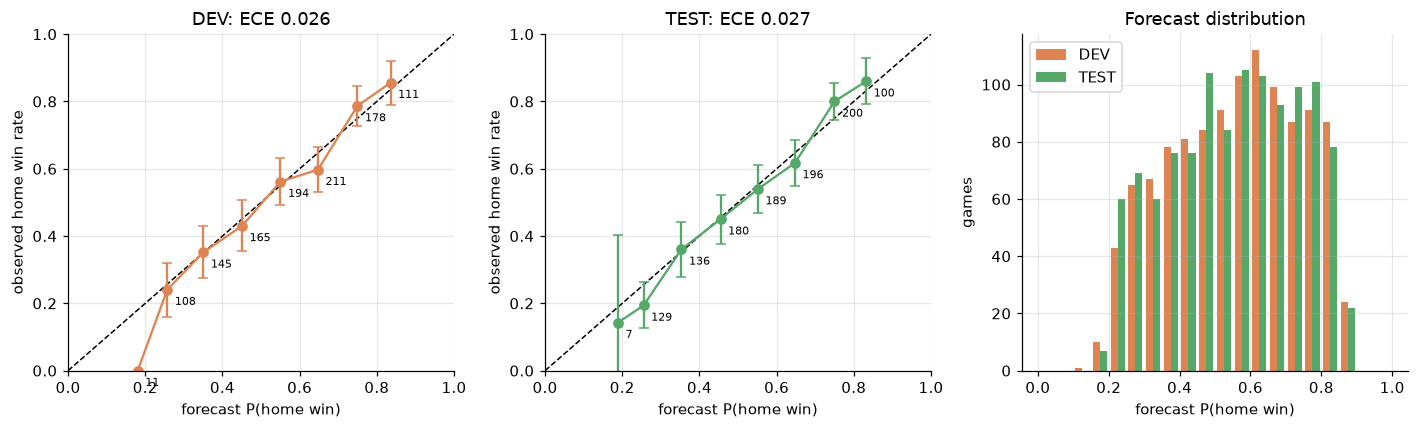

DEV: mean forecast 0.556 vs observed 0.550; forecast range 0.136-0.896
TEST: mean forecast 0.553 vs observed 0.550; forecast range 0.173-0.883


In [5]:
def ece(yy, pp, bins=10):
    b = np.minimum((pp * bins).astype(int), bins - 1)
    return sum(abs(pp[b == i].mean() - yy[b == i].mean()) * (b == i).mean() for i in range(bins) if (b == i).any())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, mask, color) in zip(axes[:2], (("DEV", DEV, "#DD8452"), ("TEST", TEST, "#55A868"))):
    rows = rgb.calibration_rows(y[mask], p[mask], CONFIG["calibration_bins"])
    xs, ys, ns = (np.array([r[k] for r in rows]) for k in ("mean_probability", "observed_home_win_rate", "games"))
    se = np.sqrt(ys * (1 - ys) / ns)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.errorbar(xs, ys, yerr=1.96 * se, fmt="o-", color=color, capsize=3)
    for xi, yi, n in zip(xs, ys, ns):
        ax.annotate(str(n), (xi, yi), textcoords="offset points", xytext=(5, -10), fontsize=7)
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="forecast P(home win)", ylabel="observed home win rate",
           title=f"{name}: ECE {ece(y[mask], p[mask]):.3f}")
axes[2].hist([p[DEV], p[TEST]], bins=20, range=(0, 1), label=["DEV", "TEST"], color=["#DD8452", "#55A868"])
axes[2].set(xlabel="forecast P(home win)", ylabel="games", title="Forecast distribution"); axes[2].legend()
plt.tight_layout(); plt.show()
for name, mask in (("DEV", DEV), ("TEST", TEST)):
    print(f"{name}: mean forecast {p[mask].mean():.3f} vs observed {y[mask].mean():.3f}; "
          f"forecast range {p[mask].min():.3f}-{p[mask].max():.3f}")

## Test 4: walk-forward TRAIN forecasts

Each TRAIN season from 2013–14 is forecast by the selected settings fitted only on earlier TRAIN seasons (these are
the `p_boost` values BAM sees). The comparison forecast is the home-win rate of the earlier seasons.

| season | fit_seasons | games | brier | home_rate_brier | skill | accuracy | roc_auc |
|---|---|---|---|---|---|---|---|
| 2013–14 | 1 | 1,153 | 0.2196 | 0.2460 | 10.7% | 65.0% | 0.696 |
| 2014–15 | 2 | 1,151 | 0.2082 | 0.2451 | 15.1% | 68.4% | 0.724 |
| 2015–16 | 3 | 1,152 | 0.2091 | 0.2405 | 13.1% | 68.5% | 0.714 |
| 2016–17 | 4 | 1,151 | 0.2237 | 0.2431 | 8.0% | 63.8% | 0.672 |
| 2017–18 | 5 | 1,150 | 0.2147 | 0.2438 | 11.9% | 65.0% | 0.700 |
| 2018–19 | 6 | 1,151 | 0.2144 | 0.2419 | 11.4% | 65.6% | 0.701 |
| 2019–20 | 7 | 982 | 0.2239 | 0.2489 | 10.0% | 65.1% | 0.684 |
| 2020–21 | 8 | 1,000 | 0.2255 | 0.2487 | 9.3% | 63.2% | 0.678 |
| 2021–22 | 9 | 1,152 | 0.2230 | 0.2489 | 10.4% | 64.3% | 0.686 |
| 2022–23 | 10 | 1,151 | 0.2277 | 0.2437 | 6.6% | 62.6% | 0.651 |
| 2023–24 | 11 | 1,115 | 0.2132 | 0.2495 | 14.5% | 64.2% | 0.719 |
| 2024–25 (DEV) | 12 | 1,123 | 0.2103 | 0.2480 | 15.2% | 66.9% | 0.724 |
| 2025–26 (TEST) | 12 | 1,137 | 0.2058 | 0.2481 | 17.1% | 67.3% | 0.740 |

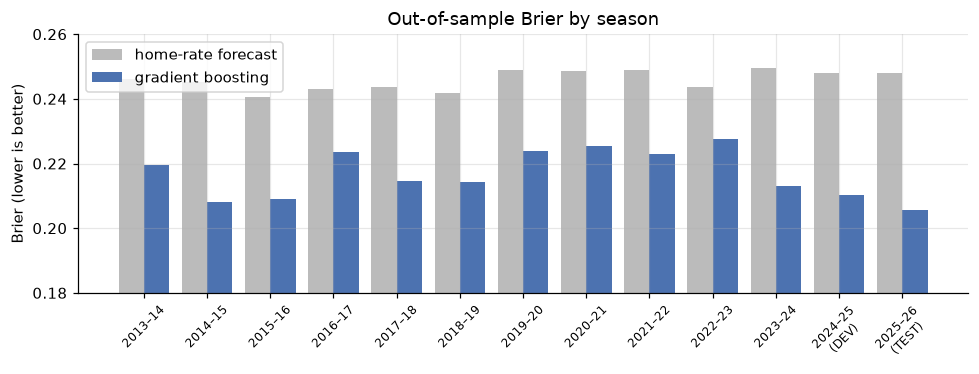

In [6]:
rows = []
for s in sorted(set(season[TRAIN]))[1:]:
    m = TRAIN & (season == s)
    prior_rate = y[TRAIN & (season < s)].mean()
    gb = score(m)
    base = rgb.score_predictions(y[m], np.full(m.sum(), prior_rate))
    rows.append({"season": rgb.season_label(int(s)), "fit_seasons": int(s - season.min()), "games": gb["games"],
                 "brier": gb["brier"], "home_rate_brier": base["brier"], "skill": 1 - gb["brier"] / base["brier"],
                 "accuracy": gb["accuracy"], "roc_auc": gb["roc_auc"]})
for name, mask in (("DEV", DEV), ("TEST", TEST)):
    gb, base = score(mask), rgb.score_predictions(y[mask], np.full(mask.sum(), home_rate))
    rows.append({"season": f"{rgb.season_label(int(season[mask][0]))} ({name})", "fit_seasons": 12, "games": gb["games"],
                 "brier": gb["brier"], "home_rate_brier": base["brier"], "skill": 1 - gb["brier"] / base["brier"],
                 "accuracy": gb["accuracy"], "roc_auc": gb["roc_auc"]})
table(rows, ["season", "fit_seasons", "games", "brier", "home_rate_brier", "skill", "accuracy", "roc_auc"],
      {"games": ",", "brier": ".4f", "home_rate_brier": ".4f", "skill": ".1%", "accuracy": ".1%", "roc_auc": ".3f"})

fig, ax = plt.subplots(figsize=(9, 3.5))
xs = np.arange(len(rows))
ax.bar(xs - .2, [r["home_rate_brier"] for r in rows], .4, label="home-rate forecast", color="#BBBBBB")
ax.bar(xs + .2, [r["brier"] for r in rows], .4, label="gradient boosting", color="#4C72B0")
ax.set_xticks(xs, [r["season"].replace(" (", "\n(") for r in rows], rotation=45, fontsize=8)
ax.set_ylim(.18, .26); ax.set_ylabel("Brier (lower is better)"); ax.legend(); ax.set_title("Out-of-sample Brier by season")
plt.tight_layout(); plt.show()

## Test 5: DEV selection among the configured candidates

From the run record: each of the four fixed settings was fitted on all of TRAIN and scored on DEV; the lowest DEV
Brier was kept (learning rate 0.05, at least 20 games per leaf).

In [7]:
best = RECORD["selected_candidate_index"]
rows = [{**r, "selected": "yes" if r["candidate_index"] == best else ""} for r in RECORD["dev_candidates"]]
table(rows, ["max_depth", "n_estimators", "brier", "log_loss", "roc_auc", "accuracy", "selected"],
      {"brier": ".4f", "log_loss": ".4f", "roc_auc": ".3f", "accuracy": ".1%"})
spread = max(r["brier"] for r in rows) - min(r["brier"] for r in rows)
print(f"Spread across candidates: {spread:.4f} Brier")

| max_depth | n_estimators | brier | log_loss | roc_auc | accuracy | selected |
|---|---|---|---|---|---|---|
| 1 | 100 | 0.2129 | 0.6145 | 0.721 | 65.7% |  |
| 1 | 200 | 0.2107 | 0.6093 | 0.724 | 66.1% |  |
| 2 | 100 | 0.2105 | 0.6091 | 0.725 | 66.3% |  |
| 2 | 200 | 0.2103 | 0.6084 | 0.724 | 66.9% | yes |

Spread across candidates: 0.0025 Brier


## Test 6: feature importance

Left: the saved model's impurity importance (share of training-loss reduction), top 20 features. Right: grouped
permutation importance on DEV: shuffle all columns of one feature group together across DEV games (30 repeats) and
measure how much DEV Brier rises. Groups: the 18 basic team features, team box-score windows (season, last 5,
last 10), player-rotation features and box-score coverage indicators.

{'basic team (18)': 18, 'coverage indicators': 36, 'player rotation': 54, 'team box: last10': 48, 'team box: last5': 48, 'team box: season': 48}


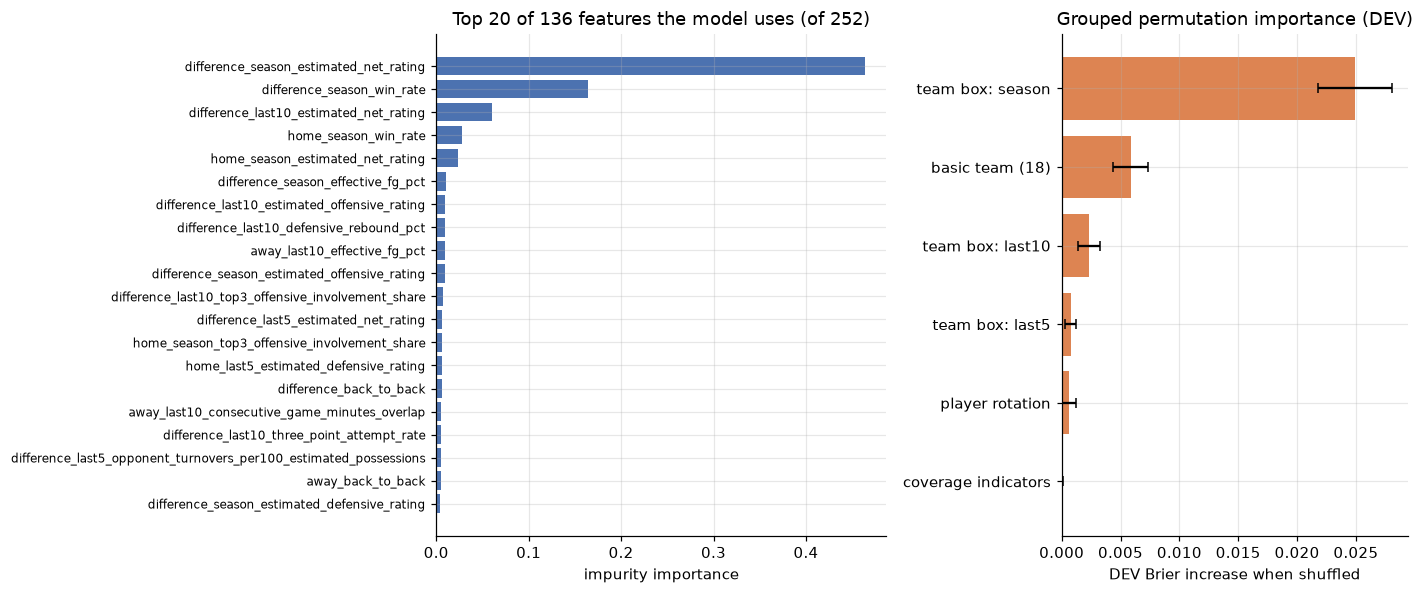

| group | features | impurity_share | dev_brier_rise |
|---|---|---|---|
| basic team (18) | 18 | 21.7% | +0.0059 |
| coverage indicators | 36 | 0.1% | +0.0000 |
| player rotation | 54 | 5.2% | +0.0006 |
| team box: last10 | 48 | 12.9% | +0.0023 |
| team box: last5 | 48 | 4.9% | +0.0008 |
| team box: season | 48 | 55.3% | +0.0249 |

In [8]:
def group(name):
    if name in rgb.BASIC_FEATURE_NAMES:
        return "basic team (18)"
    if "boxscore_coverage" in name or "boxscore_missing" in name:
        return "coverage indicators"
    if any(k in name for k in ("player_minutes", "minutes_share", "minutes_concentration", "involvement", "rotation_players", "minutes_overlap")):
        return "player rotation"
    window = name.split("_")[1]
    return f"team box: {window}"
GROUPS = defaultdict(list)
for i, n in enumerate(NAMES):
    GROUPS[group(n)].append(i)
GROUPS = dict(sorted(GROUPS.items()))
print({g: len(c) for g, c in GROUPS.items()})

importance = final.named_steps["model"].feature_importances_
top = np.argsort(importance)[::-1][:20]
used = int((importance > 0).sum())

base_brier = score(DEV)["brier"]
rng = np.random.default_rng(CONFIG["seed"])
perm = {}
for g, cols in GROUPS.items():
    rises = []
    for _ in range(30):
        Xp = X[DEV].copy()
        Xp[:, cols] = Xp[rng.permutation(DEV.sum())][:, cols]
        rises.append(rgb.score_predictions(y[DEV], final.predict_proba(Xp)[:, 1])["brier"] - base_brier)
    perm[g] = (np.mean(rises), np.std(rises))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].barh([NAMES[i] for i in top][::-1], importance[top][::-1], color="#4C72B0")
axes[0].set(xlabel="impurity importance", title=f"Top 20 of {used} features the model uses (of {len(NAMES)})")
axes[0].tick_params(axis="y", labelsize=8)
order = sorted(perm, key=lambda g: perm[g][0])
axes[1].barh(order, [perm[g][0] for g in order], xerr=[perm[g][1] for g in order], color="#DD8452", capsize=3)
axes[1].set(xlabel="DEV Brier increase when shuffled", title="Grouped permutation importance (DEV)")
plt.tight_layout(); plt.show()
share = {g: importance[c].sum() for g, c in GROUPS.items()}
table([{"group": g, "features": len(GROUPS[g]), "impurity_share": share[g], "dev_brier_rise": perm[g][0]} for g in GROUPS],
      ["group", "features", "impurity_share", "dev_brier_rise"], {"impurity_share": ".1%", "dev_brier_rise": "+.4f"})

## Test 7: wider hyperparameter sweep (DEV only)

Histogram gradient boosting with the project's other settings (log loss, at least 20 games per leaf, no early
stopping, no subsampling, missing values handled natively instead of median imputation). First, a check that it
lands near the exact model at the selected settings; then a grid over tree depth, learning rate and number of trees.

DEV Brier at the selected settings: exact model 0.2103, histogram model 0.2102 (forecast correlation 0.996)


45 fits in 261s


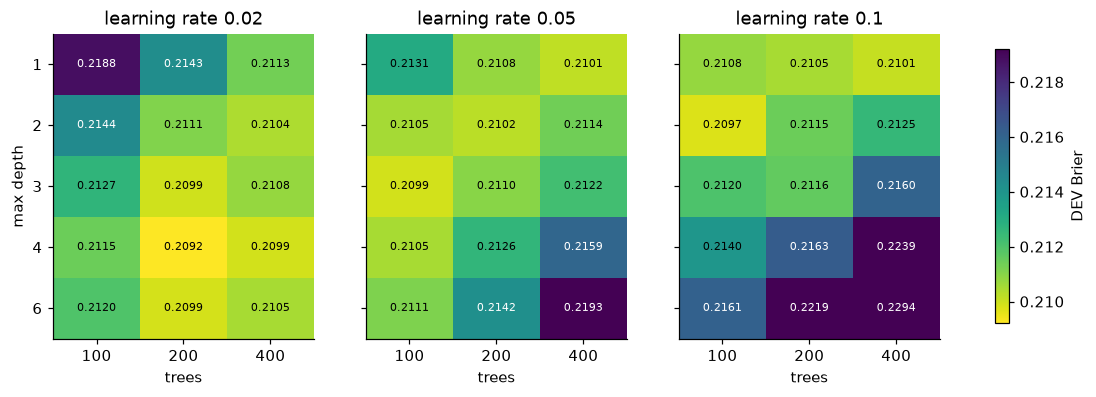

| max_depth | learning_rate | trees | dev_brier | vs_selected |
|---|---|---|---|---|
| 4 | 0.02 | 200 | 0.2092 | -0.0010 |
| 2 | 0.1 | 100 | 0.2097 | -0.0005 |
| 6 | 0.02 | 200 | 0.2099 | -0.0004 |
| 3 | 0.05 | 100 | 0.2099 | -0.0004 |
| 4 | 0.02 | 400 | 0.2099 | -0.0003 |
| 3 | 0.02 | 200 | 0.2099 | -0.0003 |
| 1 | 0.1 | 400 | 0.2101 | -0.0002 |
| 1 | 0.05 | 400 | 0.2101 | -0.0001 |

Worst: ((6, 0.1, 400), 0.22940977255511652)


In [9]:
def hgb(depth=2, trees=200, lr=.05, leaf=20, l2=0.0):
    return HistGradientBoostingClassifier(loss="log_loss", learning_rate=lr, max_iter=trees, max_depth=depth,
                                          max_leaf_nodes=None, min_samples_leaf=leaf, l2_regularization=l2,
                                          early_stopping=False, random_state=CONFIG["seed"])

def dev_brier(model, cols=slice(None), fit_mask=TRAIN):
    model.fit(X[fit_mask][:, cols], y[fit_mask])
    prob = model.predict_proba(X[DEV][:, cols])[:, 1]
    return rgb.score_predictions(y[DEV], prob), prob

sel = bundle["settings"]
proxy, proxy_p = dev_brier(hgb(sel["max_depth"], sel["n_estimators"], sel["learning_rate"]))
print(f"DEV Brier at the selected settings: exact model {base_brier:.4f}, histogram model {proxy['brier']:.4f} "
      f"(forecast correlation {np.corrcoef(proxy_p, p[DEV])[0, 1]:.3f})")

depths, rates, trees = (1, 2, 3, 4, 6), (.02, .05, .1), (100, 200, 400)
started, grid = time.time(), {}
for d in depths:
    for lr in rates:
        for t in trees:
            grid[d, lr, t] = dev_brier(hgb(d, t, lr))[0]["brier"]
print(f"{len(grid)} fits in {time.time() - started:.0f}s")

fig, axes = plt.subplots(1, len(rates), figsize=(13, 3.6), sharey=True)
lo = min(grid.values()); hi = min(max(grid.values()), lo + .01)
for ax, lr in zip(axes, rates):
    M = np.array([[grid[d, lr, t] for t in trees] for d in depths])
    im = ax.imshow(M, cmap="viridis_r", vmin=lo, vmax=hi, aspect="auto")
    for i in range(len(depths)):
        for j in range(len(trees)):
            ax.text(j, i, f"{M[i, j]:.4f}", ha="center", va="center", fontsize=7, color="w" if M[i, j] > (lo + hi) / 2 else "k")
    ax.set(xticks=range(len(trees)), xticklabels=trees, yticks=range(len(depths)), yticklabels=depths,
           xlabel="trees", title=f"learning rate {lr}"); ax.grid(False)
axes[0].set_ylabel("max depth")
fig.colorbar(im, ax=axes, label="DEV Brier", shrink=.9); plt.show()
ranked = sorted(grid.items(), key=lambda kv: kv[1])
table([{"max_depth": k[0], "learning_rate": k[1], "trees": k[2], "dev_brier": v, "vs_selected": v - proxy["brier"]}
       for k, v in ranked[:8]], ["max_depth", "learning_rate", "trees", "dev_brier", "vs_selected"],
      {"dev_brier": ".4f", "vs_selected": "+.4f"})
print("Worst:", ranked[-1])

## Test 8: feature-group ablation (DEV only)

Histogram boosting at the selected settings, fitted on TRAIN with only some feature groups. The interval is the
paired day-clustered bootstrap of the DEV Brier difference against the model with all 252 features.

In [10]:
basic = list(GROUPS["basic team (18)"])
team = [i for g, c in GROUPS.items() if g.startswith("team box") for i in c]
player, coverage = GROUPS["player rotation"], GROUPS["coverage indicators"]
difference_only = [i for i, n in enumerate(NAMES) if n.startswith("difference_") or n.startswith("diff_")]
season_window = [i for i, n in enumerate(NAMES) if n in rgb.BASIC_FEATURE_NAMES or "_season_" in n]
sets = {"all 252 features": list(range(len(NAMES))),
        "basic 18 only": basic,
        "basic + team box": basic + team,
        "basic + team box + player": basic + team + player,
        "team box only": team,
        "season-long windows only": season_window,
        "home-minus-away columns only": difference_only,
        "without player rotation": [i for i in range(len(NAMES)) if i not in set(player)],
        "without coverage indicators": [i for i in range(len(NAMES)) if i not in set(coverage)]}
forecasts = {}
for name, cols in sets.items():
    forecasts[name] = dev_brier(hgb(sel["max_depth"], sel["n_estimators"], sel["learning_rate"]), cols)[1]
boot = rgb.bootstrap_brier(y[DEV], forecasts, dates[DEV], CONFIG["bootstrap_replicates"], CONFIG["seed"], "all 252 features")
rows = []
for name, prob in forecasts.items():
    m = rgb.score_predictions(y[DEV], prob)
    interval = boot["difference_vs_reference"].get(name)
    rows.append({"features": name, "columns": len(sets[name]), "dev_brier": m["brier"], "roc_auc": m["roc_auc"],
                 "accuracy": m["accuracy"], "diff_vs_all": "" if interval is None else f"[{interval[0]:+.4f}, {interval[1]:+.4f}]"})
table(rows, ["features", "columns", "dev_brier", "roc_auc", "accuracy", "diff_vs_all"],
      {"dev_brier": ".4f", "roc_auc": ".3f", "accuracy": ".1%"})
print(f"difference-only columns found: {len(difference_only)}")

| features | columns | dev_brier | roc_auc | accuracy | diff_vs_all |
|---|---|---|---|---|---|
| all 252 features | 252 | 0.2102 | 0.724 | 66.6% |  |
| basic 18 only | 18 | 0.2122 | 0.718 | 67.1% | [-0.0008, +0.0048] |
| basic + team box | 162 | 0.2106 | 0.723 | 66.3% | [-0.0008, +0.0015] |
| basic + team box + player | 216 | 0.2103 | 0.724 | 66.6% | [-0.0001, +0.0002] |
| team box only | 144 | 0.2118 | 0.719 | 66.3% | [-0.0003, +0.0035] |
| season-long windows only | 96 | 0.2107 | 0.723 | 66.6% | [-0.0014, +0.0023] |
| home-minus-away columns only | 84 | 0.2080 | 0.731 | 67.0% | [-0.0042, -0.0004] |
| without player rotation | 198 | 0.2106 | 0.723 | 66.3% | [-0.0007, +0.0015] |
| without coverage indicators | 216 | 0.2103 | 0.724 | 66.6% | [-0.0001, +0.0002] |

difference-only columns found: 84


## Test 9: training-window length (DEV only)

Does older history help? Histogram boosting at the selected settings, fitted on only the most recent *k* TRAIN
seasons and scored on DEV.

| recent_seasons | first_season | fit_games | dev_brier | roc_auc | accuracy |
|---|---|---|---|---|---|
| 1 | 2023–24 | 1,115 | 0.2236 | 0.693 | 64.9% |
| 2 | 2022–23 | 2,266 | 0.2198 | 0.698 | 65.2% |
| 3 | 2021–22 | 3,418 | 0.2160 | 0.708 | 66.0% |
| 4 | 2020–21 | 4,418 | 0.2144 | 0.713 | 66.3% |
| 6 | 2018–19 | 6,551 | 0.2139 | 0.714 | 67.1% |
| 8 | 2016–17 | 8,852 | 0.2114 | 0.722 | 66.8% |
| 10 | 2014–15 | 11,155 | 0.2107 | 0.723 | 67.4% |
| 12 | 2012–13 | 13,457 | 0.2102 | 0.724 | 66.6% |

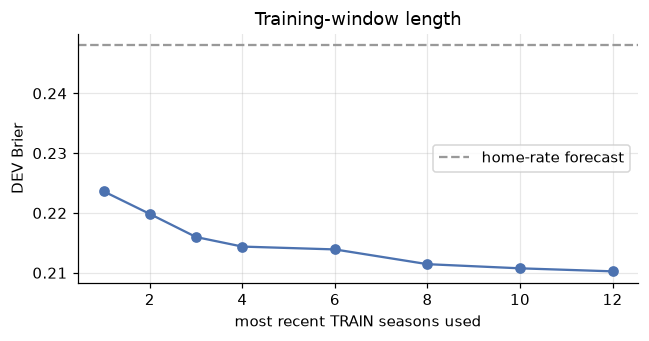

In [11]:
train_seasons = sorted(set(season[TRAIN]))
rows = []
for k in (1, 2, 3, 4, 6, 8, 10, len(train_seasons)):
    keep = TRAIN & (season >= train_seasons[-k])
    m, _ = dev_brier(hgb(sel["max_depth"], sel["n_estimators"], sel["learning_rate"]), fit_mask=keep)
    rows.append({"recent_seasons": k, "first_season": rgb.season_label(int(train_seasons[-k])), "fit_games": int(keep.sum()),
                 "dev_brier": m["brier"], "roc_auc": m["roc_auc"], "accuracy": m["accuracy"]})
table(rows, ["recent_seasons", "first_season", "fit_games", "dev_brier", "roc_auc", "accuracy"],
      {"fit_games": ",", "dev_brier": ".4f", "roc_auc": ".3f", "accuracy": ".1%"})
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot([r["recent_seasons"] for r in rows], [r["dev_brier"] for r in rows], "o-", color="#4C72B0")
ax.axhline(rgb.score_predictions(y[DEV], np.full(DEV.sum(), home_rate))["brier"], color="#999", ls="--", label="home-rate forecast")
ax.set(xlabel="most recent TRAIN seasons used", ylabel="DEV Brier", title="Training-window length"); ax.legend()
plt.tight_layout(); plt.show()

## Test 10: error analysis (saved model)

In [12]:
held = DEV | TEST
rows = []
for name, mask in (("DEV", DEV), ("TEST", TEST)):
    for month in sorted(set(d[:7] for d in dates[mask])):
        m = mask & (np.char.startswith(dates.astype(str), month))
        s = score(m)
        rows.append({"split": name, "month": month, "games": s["games"], "brier": s["brier"], "accuracy": s["accuracy"]})
table(rows, ["split", "month", "games", "brier", "accuracy"], {"brier": ".4f", "accuracy": ".1%"})

confidence = np.abs(p - .5)
edges = [0, .05, .1, .15, .2, .3, .5]
rows = []
for lo_, hi_ in zip(edges, edges[1:]):
    m = held & (confidence >= lo_) & (confidence < hi_ + (1e-9 if hi_ == .5 else 0))
    if m.any():
        favorite_won = ((p[m] >= .5) == (y[m] == 1)).mean()
        rows.append({"favorite_probability": f"{.5 + lo_:.2f}-{.5 + hi_:.2f}", "games": int(m.sum()),
                     "mean_favorite_probability": (.5 + confidence[m]).mean(), "favorite_won": favorite_won,
                     "brier": rgb.score_predictions(y[m], p[m])["brier"]})
display(Markdown("**Does the favorite win as often as forecast? (DEV + TEST)**"))
table(rows, ["favorite_probability", "games", "mean_favorite_probability", "favorite_won", "brier"],
      {"mean_favorite_probability": ".3f", "favorite_won": ".1%", "brier": ".4f"})

home_fav = held & (p >= .5)
print(f"Home team favored in {home_fav.sum() / held.sum():.1%} of DEV+TEST games; "
      f"accuracy when home favored {((y == 1) & home_fav).sum() / home_fav.sum():.1%}, "
      f"when away favored {((y == 0) & held & ~home_fav).sum() / (held & ~home_fav).sum():.1%}")

error = (p - y) ** 2
worst = np.argsort(np.where(held, error, -1))[::-1][:10]
display(Markdown("**Ten most confident misses (DEV + TEST)**"))
table([{"date": dates[i], "split": split[i].upper(), "game": teams[i], "p_home": p[i],
        "result": "home win" if y[i] else "away win"} for i in worst],
      ["date", "split", "game", "p_home", "result"], {"p_home": ".3f"})

| split | month | games | brier | accuracy |
|---|---|---|---|---|
| DEV | 2024-11 | 215 | 0.2117 | 64.7% |
| DEV | 2024-12 | 192 | 0.2091 | 68.8% |
| DEV | 2025-01 | 227 | 0.2228 | 61.7% |
| DEV | 2025-02 | 176 | 0.2127 | 67.6% |
| DEV | 2025-03 | 238 | 0.2009 | 71.0% |
| DEV | 2025-04 | 75 | 0.1964 | 69.3% |
| TEST | 2025-10 | 2 | 0.3615 | 0.0% |
| TEST | 2025-11 | 218 | 0.1852 | 70.6% |
| TEST | 2025-12 | 198 | 0.2442 | 57.6% |
| TEST | 2026-01 | 233 | 0.2324 | 58.4% |
| TEST | 2026-02 | 166 | 0.2117 | 68.1% |
| TEST | 2026-03 | 239 | 0.1748 | 77.4% |
| TEST | 2026-04 | 81 | 0.1660 | 77.8% |

**Does the favorite win as often as forecast? (DEV + TEST)**

| favorite_probability | games | mean_favorite_probability | favorite_won | brier |
|---|---|---|---|---|
| 0.50-0.55 | 363 | 0.524 | 49.3% | 0.2508 |
| 0.55-0.60 | 365 | 0.574 | 61.6% | 0.2366 |
| 0.60-0.65 | 369 | 0.624 | 61.2% | 0.2382 |
| 0.65-0.70 | 319 | 0.676 | 63.3% | 0.2341 |
| 0.70-0.80 | 615 | 0.747 | 79.0% | 0.1674 |
| 0.80-1.00 | 229 | 0.832 | 86.5% | 0.1189 |

Home team favored in 61.0% of DEV+TEST games; accuracy when home favored 68.1%, when away favored 65.5%


**Ten most confident misses (DEV + TEST)**

| date | split | game | p_home | result |
|---|---|---|---|---|
| 2024-11-23 | DEV | POR @ HOU | 0.867 | away win |
| 2026-03-07 | TEST | BKN @ DET | 0.861 | away win |
| 2025-02-01 | DEV | WAS @ MIN | 0.860 | away win |
| 2026-01-23 | TEST | IND @ OKC | 0.855 | away win |
| 2026-02-05 | TEST | WAS @ DET | 0.852 | away win |
| 2024-11-12 | DEV | ATL @ BOS | 0.851 | away win |
| 2026-02-10 | TEST | IND @ NYK | 0.850 | away win |
| 2026-03-15 | TEST | DAL @ CLE | 0.850 | away win |
| 2024-11-27 | DEV | ATL @ CLE | 0.849 | away win |
| 2025-11-17 | TEST | CHI @ DEN | 0.843 | away win |

## Test 11: why the most confident misses happened

The model has no injury or lineup input, so a natural suspect is that a key player sat. For every DEV and TEST game,
this marks each team's **core players**: its three highest minutes-per-team-game players over its earlier games that
season. A core player is **out** if he has no minutes in the game's box score.

This uses the *postgame* box score, which the model could not have seen, so it is a diagnostic, not a feature. A real
input would need pregame injury reports or confirmed lineups.

In [2]:
from evaluate_orthogonality import statistics, bootstrap as ortho_bootstrap, day_folds, logit
from collect_polymarket import load_price_observations

games_meta = {r["game_id"]: r for r in dataset.table("games")}
minutes = defaultdict(dict)                        # (game_id, side) -> player_id -> minutes
for r in dataset.table("player_box_scores"):
    if r["minutes"]:
        minutes[r["game_id"], r["side"]][r["player_id"]] = r["minutes"]
boxed = {(r["game_id"]) for r in dataset.table("box_score_games") if r["players_complete"]}

team_games = defaultdict(list)                     # (season, team) -> [(date, game_id, side)]
for g in games_meta.values():
    for side in ("home", "away"):
        team_games[g["season"], g[f"{side}_abbr"]].append((g["game_date_et"], g["game_id"], side))
for v in team_games.values():
    v.sort()

def core_out(game_id, side, k=3):
    g = games_meta[game_id]
    prior = [(gid, s) for d, gid, s in team_games[g["season"], g[f"{side}_abbr"]] if d < g["game_date_et"] and gid in boxed]
    if len(prior) < 5 or game_id not in boxed:
        return None
    total = Counter()
    for gid, s in prior:
        total.update(minutes[gid, s])
    core = [pid for pid, _ in total.most_common(k)]
    return sum(pid not in minutes[game_id, side] for pid in core)

held = DEV | TEST
out = {side: np.array([np.nan if (v := core_out(g, side) if h else None) is None else v for g, h in zip(ids, held)], dtype=float) for side in ("home", "away")}
fav_side = np.where(p >= .5, "home", "away")
fav_out = np.array([out[s][i] for i, s in enumerate(fav_side)])
dog_out = np.array([out["away" if s == "home" else "home"][i] for i, s in enumerate(fav_side)])
fav_p = np.maximum(p, 1 - p)
fav_won = (p >= .5) == (y == 1)
known = held & np.isfinite(fav_out)
print(f"Core-player status known for {known.sum():,} of {held.sum():,} DEV+TEST games")

rows = []
for label, lo_, hi_ in (("50-60%", .5, .6), ("60-70%", .6, .7), ("70%+", .7, 1.01)):
    band = known & (fav_p >= lo_) & (fav_p < hi_)
    for status, m in (("all core played", band & (fav_out == 0)), ("1+ core out", band & (fav_out > 0))):
        rows.append({"favorite_forecast": label, "favorite_status": status, "games": int(m.sum()),
                     "mean_forecast": fav_p[m].mean(), "favorite_won": fav_won[m].mean()})
display(Markdown("**Favorite win rate by whether the favorite's core players played (DEV + TEST)**"))
table(rows, ["favorite_forecast", "favorite_status", "games", "mean_forecast", "favorite_won"],
      {"mean_forecast": ".3f", "favorite_won": ".1%"})

Core-player status known for 2,165 of 2,260 DEV+TEST games


**Favorite win rate by whether the favorite's core players played (DEV + TEST)**

| favorite_forecast | favorite_status | games | mean_forecast | favorite_won |
|---|---|---|---|---|
| 50-60% | all core played | 453 | 0.548 | 56.3% |
| 50-60% | 1+ core out | 245 | 0.551 | 53.1% |
| 60-70% | all core played | 455 | 0.649 | 64.2% |
| 60-70% | 1+ core out | 203 | 0.647 | 58.1% |
| 70%+ | all core played | 588 | 0.771 | 80.4% |
| 70%+ | 1+ core out | 221 | 0.770 | 82.4% |

In [3]:
cutoff_price = {r["game_id"]: r["home_probability"] for r in load_price_observations()
                if r["record_kind"] == "cutoff" and r["home_probability"] is not None}
q = np.array([cutoff_price.get(g, np.nan) for g in ids])     # market P(home win) at tipoff - 60 min

error = (p - y) ** 2
misses = [i for i in np.argsort(np.where(held, error, -1))[::-1] if held[i]][:20]
rows = [{"date": dates[i], "split": split[i].upper(), "game": teams[i],
         "favorite": games_meta[ids[i]][f"{fav_side[i]}_abbr"], "model_fav_p": fav_p[i],
         "market_fav_p": (q[i] if fav_side[i] == "home" else 1 - q[i]) if np.isfinite(q[i]) else None,
         "fav_core_out": None if np.isnan(fav_out[i]) else int(fav_out[i]), "dog_core_out": None if np.isnan(dog_out[i]) else int(dog_out[i])} for i in misses]
display(Markdown("**Twenty most confident misses: what the market said and who sat** (core out = of top-3 minutes players)"))
table(rows, ["date", "split", "game", "favorite", "model_fav_p", "market_fav_p", "fav_core_out", "dog_core_out"],
      {"model_fav_p": ".3f", "market_fav_p": ".3f"})
miss_out = np.array([r["fav_core_out"] or 0 for r in rows])
market_lower = [r for r in rows if r["market_fav_p"] is not None and r["market_fav_p"] < r["model_fav_p"] - .05]
base_rate = (fav_out[known & (fav_p >= .7)] > 0).mean()
print(f"Favorite missing 1+ core player: {np.mean(miss_out > 0):.0%} of these 20 misses vs "
      f"{base_rate:.0%} of all games with a 70%+ favorite.")
print(f"Market was at least 5 points less confident in the favorite in {len(market_lower)} of {sum(r['market_fav_p'] is not None for r in rows)} priced misses.")

**Twenty most confident misses: what the market said and who sat** (core out = of top-3 minutes players)

| date | split | game | favorite | model_fav_p | market_fav_p | fav_core_out | dog_core_out |
|---|---|---|---|---|---|---|---|
| 2024-11-23 | DEV | POR @ HOU | HOU | 0.867 | 0.865 | 0 | 0 |
| 2026-03-07 | TEST | BKN @ DET | DET | 0.861 | 0.865 | 2 | 0 |
| 2025-02-01 | DEV | WAS @ MIN | MIN | 0.860 | 0.845 | 2 | 0 |
| 2026-01-23 | TEST | IND @ OKC | OKC | 0.855 | 0.875 |  |  |
| 2026-02-05 | TEST | WAS @ DET | DET | 0.852 | 0.885 | 0 | 0 |
| 2024-11-12 | DEV | ATL @ BOS | BOS | 0.851 | 0.905 | 0 | 1 |
| 2026-02-10 | TEST | IND @ NYK | NYK | 0.850 | 0.835 | 0 | 1 |
| 2026-03-15 | TEST | DAL @ CLE | CLE | 0.850 | 0.895 | 1 | 0 |
| 2024-11-27 | DEV | ATL @ CLE | CLE | 0.849 | 0.805 | 0 | 0 |
| 2025-11-17 | TEST | CHI @ DEN | DEN | 0.843 | 0.875 | 0 | 0 |
| 2025-02-01 | DEV | BKN @ HOU | HOU | 0.843 | 0.875 | 1 | 1 |
| 2025-03-13 | DEV | WAS @ DET | DET | 0.841 | 0.875 | 0 | 1 |
| 2025-11-01 | TEST | SAC @ MIL | MIL | 0.840 | 0.715 | 0 | 0 |
| 2025-03-16 | DEV | ORL @ CLE | CLE | 0.838 | 0.845 | 0 | 0 |
| 2025-03-19 | DEV | NOP @ MIN | MIN | 0.836 | 0.865 | 0 | 1 |
| 2024-11-04 | DEV | UTA @ CHI | CHI | 0.836 | 0.735 | 1 | 0 |
| 2025-01-10 | DEV | SAC @ BOS | BOS | 0.835 | 0.835 | 0 | 1 |
| 2024-12-25 | DEV | PHI @ BOS | BOS | 0.834 | 0.775 | 0 | 0 |
| 2025-12-01 | TEST | DAL @ DEN | DEN | 0.831 | 0.825 | 0 | 1 |
| 2025-03-10 | DEV | CHA @ MIA | MIA | 0.831 | 0.775 | 0 | 0 |

Favorite missing 1+ core player: 25% of these 20 misses vs 27% of all games with a 70%+ favorite.
Market was at least 5 points less confident in the favorite in 4 of 20 priced misses.


## Test 12: comparison with Polymarket

The market forecast is the Polymarket home-win price at **the same cutoff as the model (tipoff − 60 min)**; the
8-hour and 1-hour horizon prices are shown for reference. Polymarket coverage starts in November 2024, so only DEV and
TEST can be compared. Squared-error comparisons use the paired day-clustered bootstrap.

In [4]:
horizon = defaultdict(dict)
for r in load_price_observations():
    if r["record_kind"] == "horizon" and r["home_probability"] is not None:
        horizon[r["hours_before_tipoff"]][r["game_id"]] = r["home_probability"]
priced = held & np.isfinite(q)
rows = []
for name, mask in (("DEV", DEV & priced), ("TEST", TEST & priced), ("DEV+TEST", priced)):
    forecasts = {"polymarket (tipoff-60m)": q[mask], "gradient_boosting": p[mask]}
    boot = rgb.bootstrap_brier(y[mask], forecasts, dates[mask], 2000, CONFIG["seed"], "polymarket (tipoff-60m)")
    for model, prob in forecasts.items():
        m = rgb.score_predictions(y[mask], prob)
        diff = boot["difference_vs_reference"].get(model)
        rows.append({"split": name, "forecast": model, "games": m["games"], "brier": m["brier"], "log_loss": m["log_loss"],
                     "roc_auc": m["roc_auc"], "accuracy": m["accuracy"],
                     "minus_market": "" if diff is None else f"[{diff[0]:+.4f}, {diff[1]:+.4f}]"})
    for hours in (8.0, 1.0):
        h = np.array([horizon[hours].get(g, np.nan) for g in ids])
        mm = mask & np.isfinite(h)
        m = rgb.score_predictions(y[mm], h[mm])
        rows.append({"split": name, "forecast": f"polymarket ({hours:g}h before)", "games": m["games"], "brier": m["brier"],
                     "log_loss": m["log_loss"], "roc_auc": m["roc_auc"], "accuracy": m["accuracy"], "minus_market": ""})
table(rows, ["split", "forecast", "games", "brier", "log_loss", "roc_auc", "accuracy", "minus_market"],
      {"games": ",", "brier": ".4f", "log_loss": ".4f", "roc_auc": ".3f", "accuracy": ".1%"})
print("minus_market: 95% interval of Brier(boosting) - Brier(market); positive = market better.")

| split | forecast | games | brier | log_loss | roc_auc | accuracy | minus_market |
|---|---|---|---|---|---|---|---|
| DEV | polymarket (tipoff-60m) | 1,121 | 0.1990 | 0.5814 | 0.755 | 69.0% |  |
| DEV | gradient_boosting | 1,121 | 0.2098 | 0.6072 | 0.725 | 67.0% | [+0.0049, +0.0166] |
| DEV | polymarket (8h before) | 1,086 | 0.2020 | 0.5884 | 0.748 | 68.6% |  |
| DEV | polymarket (1h before) | 1,121 | 0.1990 | 0.5814 | 0.755 | 69.0% |  |
| TEST | polymarket (tipoff-60m) | 1,132 | 0.1941 | 0.5689 | 0.767 | 69.3% |  |
| TEST | gradient_boosting | 1,132 | 0.2059 | 0.5993 | 0.740 | 67.2% | [+0.0055, +0.0180] |
| TEST | polymarket (8h before) | 1,131 | 0.1953 | 0.5715 | 0.764 | 69.2% |  |
| TEST | polymarket (1h before) | 1,132 | 0.1941 | 0.5689 | 0.767 | 69.3% |  |
| DEV+TEST | polymarket (tipoff-60m) | 2,253 | 0.1966 | 0.5751 | 0.761 | 69.2% |  |
| DEV+TEST | gradient_boosting | 2,253 | 0.2078 | 0.6032 | 0.732 | 67.1% | [+0.0069, +0.0156] |
| DEV+TEST | polymarket (8h before) | 2,217 | 0.1986 | 0.5798 | 0.756 | 68.9% |  |
| DEV+TEST | polymarket (1h before) | 2,253 | 0.1966 | 0.5751 | 0.761 | 69.2% |  |

minus_market: 95% interval of Brier(boosting) - Brier(market); positive = market better.


### Where we diverge, and who is right

| abs_gap | games | model_brier | market_brier | model_closer | pick_disagreements | model_pick_right |
|---|---|---|---|---|---|---|
| 0.00-0.05 | 828 | 0.2132 | 0.2121 | 44.0% | 24 | 37.5% |
| 0.05-0.10 | 655 | 0.1944 | 0.1898 | 36.8% | 73 | 43.8% |
| 0.10-0.15 | 422 | 0.1994 | 0.1815 | 31.3% | 83 | 43.4% |
| 0.15-0.20 | 198 | 0.2229 | 0.1983 | 32.3% | 61 | 52.5% |
| 0.20+ | 150 | 0.2406 | 0.1804 | 28.0% | 75 | 34.7% |

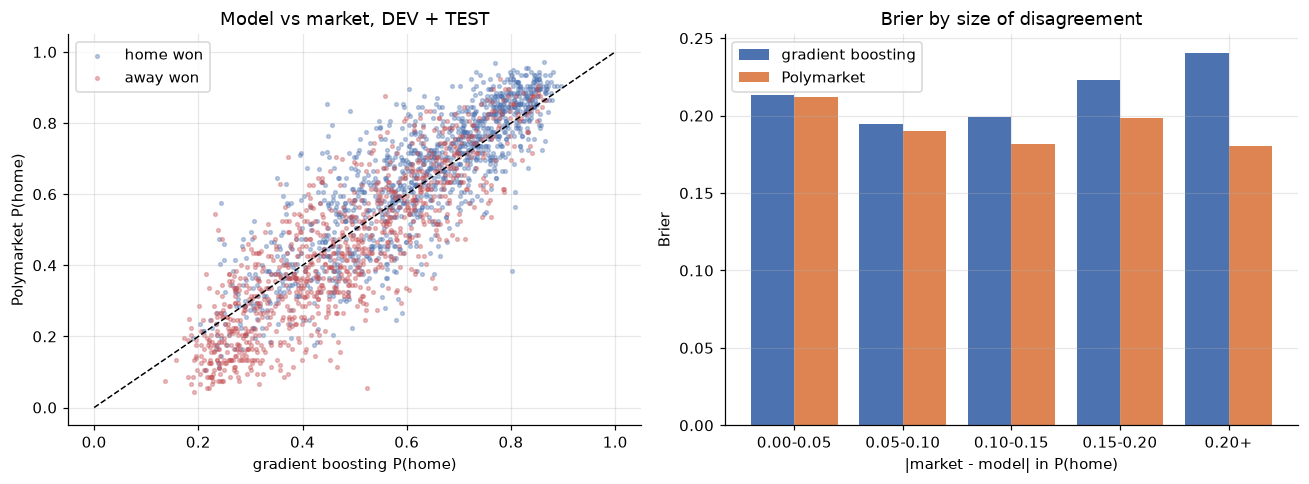

**Ten games where the market beat us most**

| date | game | model_p_home | market_p_home | result | home_core_out | away_core_out |
|---|---|---|---|---|---|---|
| 2025-11-04 | CHA @ NOP | 0.244 | 0.575 | home win | 0 | 1 |
| 2026-03-12 | DAL @ MEM | 0.654 | 0.335 | away win | 2 | 0 |
| 2025-11-19 | CHA @ IND | 0.240 | 0.475 | home win | 0 | 0 |
| 2024-11-22 | BKN @ PHI | 0.351 | 0.645 | home win | 0 | 0 |
| 2025-01-14 | NOP @ CHI | 0.762 | 0.535 | away win | 0 | 0 |
| 2024-12-03 | PHI @ CHA | 0.649 | 0.365 | away win | 1 | 0 |
| 2026-01-02 | DEN @ CLE | 0.447 | 0.855 | home win | 0 | 1 |
| 2024-12-30 | DAL @ SAC | 0.397 | 0.715 | home win | 0 | 2 |
| 2024-11-13 | MEM @ LAL | 0.395 | 0.710 | home win | 0 | 0 |
| 2026-01-18 | CHA @ DEN | 0.711 | 0.475 | away win | 0 | 0 |

**Ten games where we beat the market most**

| date | game | model_p_home | market_p_home | result | home_core_out | away_core_out |
|---|---|---|---|---|---|---|
| 2026-01-05 | DEN @ PHI | 0.558 | 0.875 | away win | 0 | 3 |
| 2026-03-15 | POR @ PHI | 0.579 | 0.245 | home win | 1 | 0 |
| 2025-02-12 | GSW @ DAL | 0.591 | 0.265 | home win | 1 | 1 |
| 2026-01-23 | DEN @ MIL | 0.372 | 0.705 | away win | 1 | 2 |
| 2024-12-23 | BOS @ ORL | 0.422 | 0.175 | home win | 1 | 1 |
| 2026-03-23 | HOU @ CHI | 0.495 | 0.225 | home win | 1 | 0 |
| 2025-02-13 | OKC @ MIN | 0.459 | 0.205 | home win | 1 | 0 |
| 2024-11-20 | PHI @ MEM | 0.802 | 0.385 | home win | 0 | 1 |
| 2025-02-07 | SAS @ CHA | 0.427 | 0.185 | home win | 1 | 0 |
| 2025-11-10 | CLE @ MIA | 0.558 | 0.280 | home win | 0 | 0 |

Model's favorite missing 1+ core player: 45% of the market's best 10% of games, 35% of our best 10%, 31% of all priced games.
Games each side is closer: model 37.4%, market 62.6%


In [5]:
gap = q - p                                   # market minus model, P(home)
ours_better = (p - y) ** 2 < (q - y) ** 2
edges = [0, .05, .10, .15, .20, 1]
rows = []
for lo_, hi_ in zip(edges, edges[1:]):
    m = priced & (np.abs(gap) >= lo_) & (np.abs(gap) < hi_)
    disagree = m & ((p >= .5) != (q >= .5))
    rows.append({"abs_gap": f"{lo_:.2f}-{hi_:.2f}" if hi_ < 1 else f"{lo_:.2f}+", "games": int(m.sum()),
                 "model_brier": rgb.score_predictions(y[m], p[m])["brier"], "market_brier": rgb.score_predictions(y[m], q[m])["brier"],
                 "model_closer": ours_better[m].mean(), "pick_disagreements": int(disagree.sum()),
                 "model_pick_right": (((p >= .5) == (y == 1))[disagree]).mean() if disagree.any() else None})
table(rows, ["abs_gap", "games", "model_brier", "market_brier", "model_closer", "pick_disagreements", "model_pick_right"],
      {"model_brier": ".4f", "market_brier": ".4f", "model_closer": ".1%", "model_pick_right": ".1%"})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for outcome, color, label in ((1, "#4C72B0", "home won"), (0, "#C44E52", "away won")):
    m = priced & (y == outcome)
    ax.scatter(p[m], q[m], s=6, alpha=.35, color=color, label=label)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="gradient boosting P(home)", ylabel="Polymarket P(home)", title="Model vs market, DEV + TEST"); ax.legend()
ax = axes[1]
labels_ = [r["abs_gap"] for r in rows]; xs = np.arange(len(rows))
ax.bar(xs - .2, [r["model_brier"] for r in rows], .4, label="gradient boosting", color="#4C72B0")
ax.bar(xs + .2, [r["market_brier"] for r in rows], .4, label="Polymarket", color="#DD8452")
ax.set_xticks(xs, labels_); ax.set(xlabel="|market - model| in P(home)", ylabel="Brier", title="Brier by size of disagreement"); ax.legend()
plt.tight_layout(); plt.show()

advantage = (p - y) ** 2 - (q - y) ** 2         # positive: market better on this game
def extremes(order, title):
    rows = [{"date": dates[i], "game": teams[i], "model_p_home": p[i], "market_p_home": q[i],
             "result": "home win" if y[i] else "away win",
             "home_core_out": None if np.isnan(out["home"][i]) else int(out["home"][i]), "away_core_out": None if np.isnan(out["away"][i]) else int(out["away"][i])} for i in order[:10]]
    display(Markdown(title))
    table(rows, ["date", "game", "model_p_home", "market_p_home", "result", "home_core_out", "away_core_out"],
          {"model_p_home": ".3f", "market_p_home": ".3f"})
idx = np.flatnonzero(priced)
extremes(idx[np.argsort(-advantage[idx])], "**Ten games where the market beat us most**")
extremes(idx[np.argsort(advantage[idx])], "**Ten games where we beat the market most**")

top = idx[advantage[idx] >= np.quantile(advantage[idx], .9)]
bottom = idx[advantage[idx] <= np.quantile(advantage[idx], .1)]
model_fav_out = lambda sel: np.mean([fav_out[i] > 0 for i in sel if np.isfinite(fav_out[i])])
print(f"Model's favorite missing 1+ core player: {model_fav_out(top):.0%} of the market's best 10% of games, "
      f"{model_fav_out(bottom):.0%} of our best 10%, {model_fav_out(idx):.0%} of all priced games.")
print(f"Games each side is closer: model {ours_better[priced].mean():.1%}, market {1 - ours_better[priced].mean():.1%}")

### Is there orthogonal information?

`scripts/evaluate_orthogonality.py` statistics, in both directions. *Base* is the forecast being extended,
*delta* = logit(other) − logit(base). If the other forecast adds nothing, the coefficient on delta is 0 and the
out-of-fold Brier gain (day-grouped 5-fold logistic recalibration of base + delta) is ≤ 0. Intervals: 500
day-clustered bootstrap replicates.

In [6]:
yp, pb, pq_, dp = y[priced], p[priced], q[priced], dates[priced]
folds = day_folds(dp, 5, CONFIG["seed"])
rows = []
for name, base, other in (("market adds to boosting", pb, pq_), ("boosting adds to market", pq_, pb)):
    s = statistics(base, other, yp, folds)
    iv = ortho_bootstrap(base, other, yp, dp, 500, CONFIG["seed"])
    rows.append({"direction": name, "logit_corr": s["logit_corr"], "delta_coef": s["delta_coef"],
                 "coef_95": f"[{iv['delta_coef'][0]:+.2f}, {iv['delta_coef'][1]:+.2f}]", "lr_p": s["lr_p"],
                 "corr_delta_residual": s["delta_residual"], "oof_brier_gain": s["oof_brier_gain"]})
table(rows, ["direction", "logit_corr", "delta_coef", "coef_95", "lr_p", "corr_delta_residual", "oof_brier_gain"],
      {"logit_corr": ".3f", "delta_coef": "+.3f", "lr_p": ".2g", "corr_delta_residual": "+.3f", "oof_brier_gain": "+.4f"})

from sklearn.linear_model import LogisticRegression
features = np.column_stack((logit(pb), logit(pq_)))
blend = np.zeros(len(yp)); weights = []
for f in np.unique(folds):
    model = LogisticRegression(C=1e6, max_iter=2000).fit(features[folds != f], yp[folds != f])
    blend[folds == f] = model.predict_proba(features[folds == f])[:, 1]; weights.append(model.coef_[0])
w = np.mean(weights, axis=0)
display(Markdown("**Out-of-fold blend of the two log-odds (DEV + TEST, folds by game day)**"))
table([{"forecast": n, "brier": rgb.score_predictions(yp, v)["brier"]} for n, v in
       (("gradient boosting", pb), ("Polymarket", pq_), ("blend", blend))], ["forecast", "brier"], {"brier": ".4f"})
print(f"Average blend weights on log-odds: boosting {w[0]:+.2f}, market {w[1]:+.2f}")

| direction | logit_corr | delta_coef | coef_95 | lr_p | corr_delta_residual | oof_brier_gain |
|---|---|---|---|---|---|---|
| market adds to boosting | 0.875 | +1.013 | [+0.81, +1.21] | 2.1e-28 | +0.231 | +0.0107 |
| boosting adds to market | 0.875 | +0.005 | [-0.26, +0.27] | 0.97 | -0.003 | -0.0004 |

**Out-of-fold blend of the two log-odds (DEV + TEST, folds by game day)**

| forecast | brier |
|---|---|
| gradient boosting | 0.2078 |
| Polymarket | 0.1966 |
| blend | 0.1974 |

Average blend weights on log-odds: boosting +0.00, market +1.01


## Data history: how far back, and would more help?

The model's data starts in **2012–13**: ESPN regular-season schedules (`config/history_2012.json`, `config/seasonal.json`),
ESPN summary box scores with NBA.com replacements for invalid ESPN boxes. Polymarket prices start in November 2024.

Test 9 measured DEV Brier against the number of TRAIN seasons. A power law fitted to those eight points estimates
what more seasons could give. This is an extrapolation of eight points, and older seasons come from a different era
(home teams won about 60% before 2019, 55% since), so treat it as an optimistic bound.

| extra_seasons | back_to | fit_games | projected_dev_brier | gain |
|---|---|---|---|---|
| 0 | 2012–13 | 13,457 | 0.2100 | +0.0000 |
| 5 | 2007–08 | 19,207 | 0.2087 | +0.0013 |
| 10 | 2002–03 | 24,957 | 0.2078 | +0.0022 |
| 15 | 1997–98 | 30,707 | 0.2071 | +0.0029 |

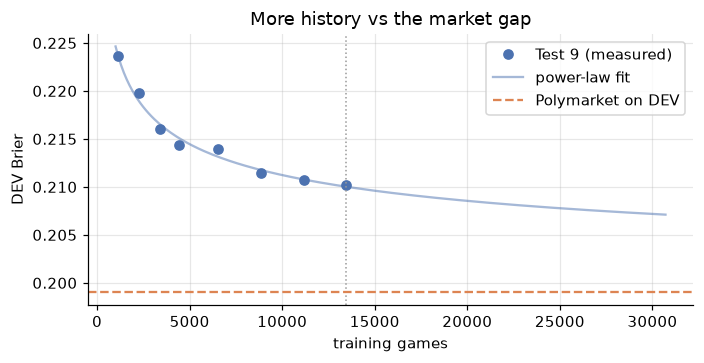

Fitted asymptote with unlimited same-kind data: 0.1950


In [7]:
from scipy.optimize import curve_fit
# Test 9 results above (fit games, DEV Brier), histogram boosting at the selected settings.
n = np.array([1115, 2266, 3418, 4418, 6551, 8852, 11155, 13457.])
b = np.array([.2236, .2198, .2160, .2144, .2139, .2114, .2107, .2102])
law = lambda n, a, c, k: a + c * n ** (-k)
params, _ = curve_fit(law, n, b, p0=[.205, 1, .5], maxfev=20000)
per_season = 1150
rows = [{"extra_seasons": e, "back_to": rgb.season_label(2012 - e), "fit_games": int(13457 + e * per_season),
         "projected_dev_brier": law(13457 + e * per_season, *params)} for e in (0, 5, 10, 15)]
for r in rows:
    r["gain"] = rows[0]["projected_dev_brier"] - r["projected_dev_brier"]
table(rows, ["extra_seasons", "back_to", "fit_games", "projected_dev_brier", "gain"],
      {"fit_games": ",", "projected_dev_brier": ".4f", "gain": "+.4f"})
grid = np.linspace(1000, 13457 + 15 * per_season, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(n, b, "o", color="#4C72B0", label="Test 9 (measured)")
ax.plot(grid, law(grid, *params), "-", color="#4C72B0", alpha=.5, label="power-law fit")
ax.axvline(13457, color="#999", ls=":", lw=1)
ax.axhline(rgb.score_predictions(y[priced & DEV], q[priced & DEV])["brier"], color="#DD8452", ls="--", label="Polymarket on DEV")
ax.set(xlabel="training games", ylabel="DEV Brier", title="More history vs the market gap"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Fitted asymptote with unlimited same-kind data: {params[0]:.4f}")

## Summary

Results as of the run on 2026-11-10 (dataset `4e5ba4eb0554`).

- **Integrity (Test 1):** all checks pass. The saved model reproduces every published forecast (max difference 3e-16), no DEV or TEST game is in any fit, and the model file matches the release checksum.
- **Headline (Test 2):** DEV Brier 0.2103 and TEST Brier 0.2058, against about 0.248 for the TRAIN home-win rate. The paired improvement interval excludes zero on both splits (TEST [−0.052, −0.033]). TEST AUC is 0.740 and accuracy 67.3%.
- **Calibration (Test 3):** the average is calibrated (TEST mean forecast 0.553 vs 0.550 observed). The weakest region is near-toss-ups: favorites forecast at 50–55% won 49% (Test 10).
- **Stability (Test 4):** every walk-forward TRAIN season beats the home-rate forecast, with skill from 7% to 15%.
- **What matters (Test 6):** season-long team box-score windows dominate: 55% of impurity importance, and shuffling them raises DEV Brier by 0.025. The 18 basic features come next (+0.006). Player-rotation and coverage-indicator features barely move DEV Brier.
- **Hyperparameters (Tests 5, 7):** the four configured candidates differ by 0.0025 DEV Brier, and the best of 45 wider settings improves on the selected one by only 0.0010. Deep, fast-learning models overfit (depth 6, learning rate 0.1, 400 trees: 0.229). Tuning is not where the remaining error is.
- **Feature sets (Test 8):** keeping only the 84 home-minus-away columns gave DEV Brier 0.2080 vs 0.2102 with all 252 features. Its paired interval [−0.0042, −0.0004] is the only one that excludes zero. This is one DEV comparison among nine, so it is a candidate to confirm, not a result.
- **History (Test 9):** more seasons help steadily: one season scores 0.2236 on DEV and all twelve score 0.2102, so the older seasons are worth keeping.
- **Errors (Test 10):** TEST error is highest in December–January (Brier 0.24) and lowest in March–April (about 0.17). Early and midseason games are hardest. The model has no injury, lineup or market information, which is what the text and market signals are meant to add.
- **Confident misses (Test 11):** the 20 worst misses were mostly genuine upsets, not availability surprises. The market was about as confident in 16 of the 20, and the favorite was missing a core player in only 25% of them (vs 27% of all 70%+ favorites). Absences do matter for moderate favorites: 60–70% favorites won 64% with their core intact and 58% without one.
- **Polymarket (Test 12):** at the same cutoff (tipoff − 60 min) the market beats the model on both splits: DEV 0.1990 vs 0.2098, TEST 0.1941 vs 0.2059, paired difference [+0.007, +0.016] on DEV+TEST. The market is closer to the outcome in 63% of games, and its edge grows with disagreement: when the forecasts differ by 20+ points, Brier is 0.180 for the market vs 0.241 for the model. Even the 8-hour-early price (0.1986) beats the model. In the market's best 10% of games, the model's favorite was missing a core player 45% of the time (31% overall), so part of the market's edge is availability news.
- **Orthogonality:** one-directional. The market adds to boosting (coefficient +1.01, out-of-fold Brier gain +0.0107), but boosting adds nothing to the market (coefficient +0.005, interval [−0.26, +0.27], gain −0.0004). An out-of-fold blend puts zero weight on boosting. Everything the model knows is already in the price; the market knows more.
- **More history:** the data starts in 2012–13. Extrapolating Test 9, ten more seasons (back to 2002–03) would give at most about 0.002 DEV Brier, a fifth of the 0.011 market gap, and older seasons come from a higher home-advantage era. Pregame availability (injury reports, confirmed lineups) and market or text signals are the more promising route to a lower Brier.